# 20 时间序列数据准备

> **模块**：时间序列 ｜ **数据**：`bitcoin_data.csv` ｜ **依赖**：numpy、pandas、statsmodels

## 1. 问题背景

数据准备是对原始数据进行转换的一种做法，以便数据科学家可以通过机器学习算法运行转化后的数据。时间序列数据集通常需要经过清理和特征工程才能产生有用的见解。

时间序列数据集可能包含缺失值或异常值，因此需要数据准备和清理阶段。由于时间序列数据具有时间特性，因此仅有某些统计方法适用于时间序列数据处理。良好的时间序列数据准备可以产生干净且有组织的数据，从而便于更实用、更准确地预测。


## 2. 学习目标

- 掌握时间序列数据的处理
- 掌握时间序列数据的分析和分解
- 掌握时间序列数据的平稳性检验


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 时间序列数据准备

#### 4.1.1 导入数据

现有比特币历史数据，该数据是每隔1分钟进行交易的特定比特币交易所的历史数据，保存在./experiment/data/data.csv文件中。


In [1]:
import pandas as pd, matplotlib.pyplot as plt, warnings
plt.rcParams['font.sans-serif']=['SimHei'] 
plt.rcParams['axes.unicode_minus']=False
pd.set_option('display.float_format', lambda x: '%.2f' % x) #去除科学计数法

data = pd.read_csv('../data/bitcoin_data.csv')
data = data.drop(columns = data.columns[0])
print('数据形状：',data.shape)
data.T

数据形状： (2842336, 2)


,0,1,2,3,4,5,6,7,8,9,...,2842326,2842327,2842328,2842329,2842330,2842331,2842332,2842333,2842334,2842335
Timestamp,1325317920.00,1325317980.00,1325318040.00,1325318100.00,1325318160.00,1325318220.00,1325318280.00,1325318340.00,1325318400.00,1325318460.00,...,1496245800.00,1496245860.00,1496245920.00,1496245980.00,1496246040.00,1496246100.00,1496246160.00,1496246220.00,1496246280.00,1496246340.00
Price,4.39,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2319.98,2315.90,2307.80,2309.08,2308.95,2312.05,2314.34,2301.02,2293.89,2299.95


#### 4.1.2 缺失值处理

##### 4.1.2.1 检查缺失值

In [2]:
# 查看是否有空值，将各列中有空值的个数统计
data.isnull().sum()

Timestamp          0
Price        1190482
dtype: int64

##### 4.1.2.2 缺失值处理

对于比特币价格（Price）变量使用向上填充（根据上期数值填充）缺失值。

In [3]:
# method='ffill'表示用前一个非缺失值去填充该缺失值
# data['Price'].fillna(method='ffill', inplace=True)  #被弃用
data['Price'].ffill(inplace=True)

#### 4.1.3 时间戳与周期

##### 4.1.3.1 时间戳

时间戳是自1970 年1月1日（00:00:00 GMT）以来的秒数，也被称为Unix时间戳（Unix Timestamp）。

例如，1451577600表示的时间就是：2016-01-01 00:00:00。

本数据集的Timestamp列的日期时间就是使用Unix时间戳表示。

pandas中时间戳的类是Timestamp，它是python基本库datetime的datetime类的替代品，在很多情况下二者可以互换。Timestamp类可以作为DatetimeIndex以及时间序列导向的数据结构的输入类型。

In [4]:
# 将Unix时间戳转换成datetime日期时间， unit='s'表示精度是秒
print('转换前类型',type(data.Timestamp[0]))
data.Timestamp = pd.to_datetime(data.Timestamp, unit='s')
print('转换后类型',type(data.Timestamp[0]))
data.T

转换前类型 <class 'numpy.int64'>
转换后类型 <class 'pandas._libs.tslibs.timestamps.Timestamp'>


,0,1,2,3,4,5,6,7,8,9,...,2842326,2842327,2842328,2842329,2842330,2842331,2842332,2842333,2842334,2842335
Timestamp,2011-12-31 07:52:00,2011-12-31 07:53:00,2011-12-31 07:54:00,2011-12-31 07:55:00,2011-12-31 07:56:00,2011-12-31 07:57:00,2011-12-31 07:58:00,2011-12-31 07:59:00,2011-12-31 08:00:00,2011-12-31 08:01:00,...,2017-05-31 15:50:00,2017-05-31 15:51:00,2017-05-31 15:52:00,2017-05-31 15:53:00,2017-05-31 15:54:00,2017-05-31 15:55:00,2017-05-31 15:56:00,2017-05-31 15:57:00,2017-05-31 15:58:00,2017-05-31 15:59:00
Price,4.39,4.39,4.39,4.39,4.39,4.39,4.39,4.39,4.39,4.39,...,2319.98,2315.90,2307.80,2309.08,2308.95,2312.05,2314.34,2301.02,2293.89,2299.95


##### 4.1.3.2 周期

DataFrame.resample(freq)，将数据基于时间列以freq作为频度对全局数据做重采样，计算出分段数据和、均值、方差等指标。

In [23]:
# data.index = data['Timestamp']
# # 对数据进行重采样，'D'表示以天为单位,first()表示基于日期偏移选择时间序列数据的初始时段
# df = data.resample('D').first()
df = data
df_month = df.resample('M').first()          # 月末（旧别名）
df_Q = df.resample('Q-DEC').first()      # 季末（以 12 月为年末）
df_year  = df.resample('A-DEC').first()      # 年末

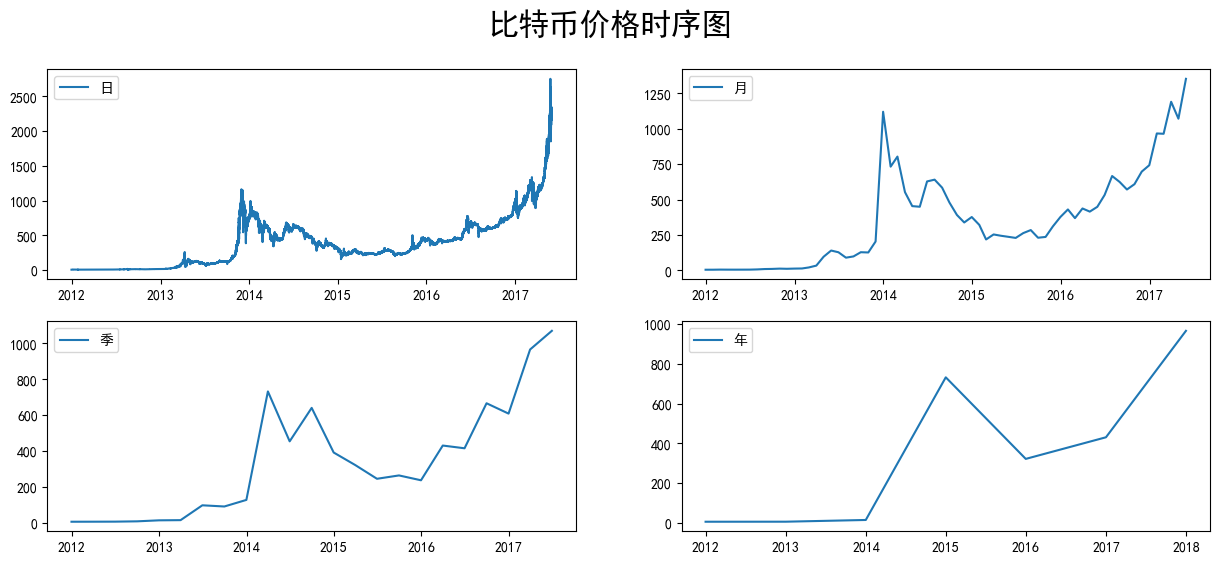

In [8]:

fig = plt.figure(figsize=[15, 6])
# 设置总标题
plt.suptitle('比特币价格时序图', fontsize=22)
d = [df.Price,df_month.Price,df_Q.Price,df_year.Price]
label = ['日','月','季','年']
# 使用for循环绘制比特币价格的按日、月、季、年的时序图
for i in range(4):
    plt.subplot(2,2,i+1)
    plt.plot(d[i], label=label[i])
    # 添加图例
    plt.legend()

##### 4.1.3.3 时间信息

转换成格式Timestamp之后就可以用：
- pandas.Series.dt.year获取数据中的年份信息
- pandas.Series.dt.month获取月信息
- pandas.Series.dt.day获取日信息
- pandas.Series.dt.weekday获取星期信息，星期一= 0，星期日= 6
- pandas.Series.dt.hour获取小时信息
- pandas.Series.dt.floor()函数将给定系列对象的日期时间数据设置为指定的频率。

In [9]:
# 在data中新增五列
d = data.copy()
d['month'] = d['Timestamp'].dt.month
d['day'] = d['Timestamp'].dt.day
d['years'] = d['Timestamp'].dt.year
d['weekday'] = d['Timestamp'].dt.weekday+1
d

,Timestamp,Price,month,day,years,weekday
Timestamp,,,,,,
2011-12-31 07:52:00,2011-12-31 07:52:00,4.39,12,31,2011,6
2011-12-31 07:53:00,2011-12-31 07:53:00,4.39,12,31,2011,6
2011-12-31 07:54:00,2011-12-31 07:54:00,4.39,12,31,2011,6
2011-12-31 07:55:00,2011-12-31 07:55:00,4.39,12,31,2011,6
2011-12-31 07:56:00,2011-12-31 07:56:00,4.39,12,31,2011,6
...,...,...,...,...,...,...
2017-05-31 15:55:00,2017-05-31 15:55:00,2312.05,5,31,2017,3
2017-05-31 15:56:00,2017-05-31 15:56:00,2314.34,5,31,2017,3
2017-05-31 15:57:00,2017-05-31 15:57:00,2301.02,5,31,2017,3


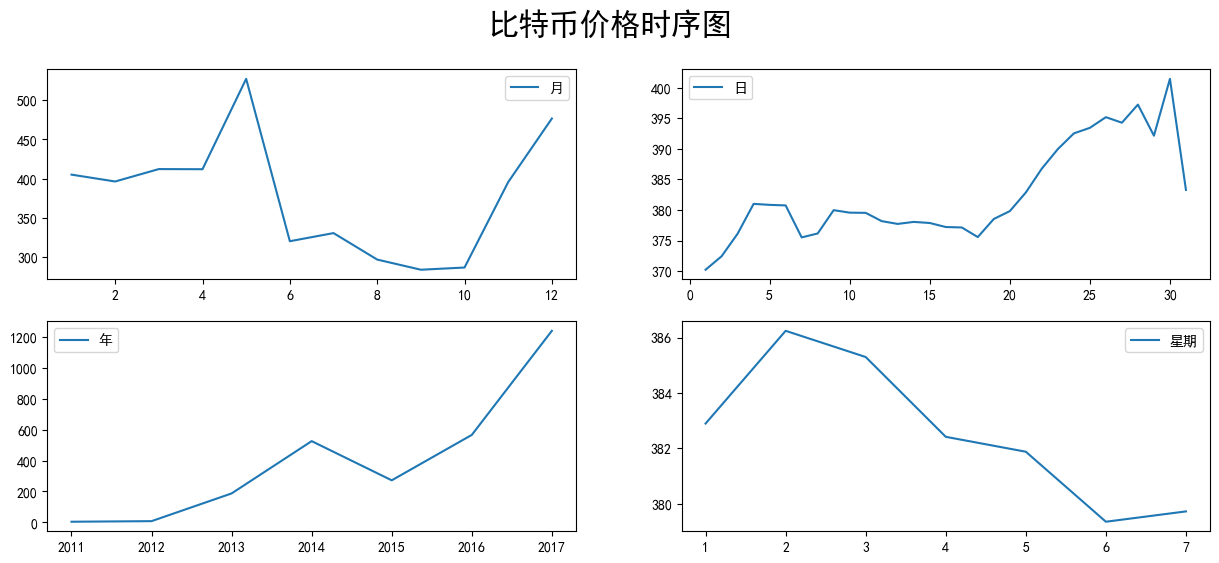

In [10]:

fig = plt.figure(figsize=[15, 6])
# 设置总标题
plt.suptitle('比特币价格时序图', fontsize=22)
s = ['month','day','years','weekday']
label = ['月','日','年','星期']
# 使用for循环绘制比特币价格的按日、月、季、年的时序图
for i in range(4):
    plt.subplot(2,2,i+1)
    res = d.groupby(by = s[i])['Price'].mean()
    plt.plot(res, label=label[i])
    # 添加图例
    plt.legend()

#### 4.1.4 索引

In [11]:
data.index

DatetimeIndex(['2011-12-31 07:52:00', '2011-12-31 07:53:00',
               '2011-12-31 07:54:00', '2011-12-31 07:55:00',
               '2011-12-31 07:56:00', '2011-12-31 07:57:00',
               '2011-12-31 07:58:00', '2011-12-31 07:59:00',
               '2011-12-31 08:00:00', '2011-12-31 08:01:00',
               ...
               '2017-05-31 15:50:00', '2017-05-31 15:51:00',
               '2017-05-31 15:52:00', '2017-05-31 15:53:00',
               '2017-05-31 15:54:00', '2017-05-31 15:55:00',
               '2017-05-31 15:56:00', '2017-05-31 15:57:00',
               '2017-05-31 15:58:00', '2017-05-31 15:59:00'],
              dtype='datetime64[ns]', name='Timestamp', length=2842336, freq=None)

In [12]:
# 指定开始和停止日期
data['2015-12-31':'2016-1-2']

,Timestamp,Price
Timestamp,,
2015-12-31 00:00:00,2015-12-31 00:00:00,425.94
2015-12-31 00:01:00,2015-12-31 00:01:00,425.94
2015-12-31 00:02:00,2015-12-31 00:02:00,426.99
2015-12-31 00:03:00,2015-12-31 00:03:00,425.69
2015-12-31 00:04:00,2015-12-31 00:04:00,426.13
...,...,...
2016-01-02 23:55:00,2016-01-02 23:55:00,433.15
2016-01-02 23:56:00,2016-01-02 23:56:00,433.39
2016-01-02 23:57:00,2016-01-02 23:57:00,433.39


In [13]:
# 指定开始和停止日期时间
data['2015-12-31':'2016-1-2 23:00:00']

,Timestamp,Price
Timestamp,,
2015-12-31 00:00:00,2015-12-31 00:00:00,425.94
2015-12-31 00:01:00,2015-12-31 00:01:00,425.94
2015-12-31 00:02:00,2015-12-31 00:02:00,426.99
2015-12-31 00:03:00,2015-12-31 00:03:00,425.69
2015-12-31 00:04:00,2015-12-31 00:04:00,426.13
...,...,...
2016-01-02 22:56:00,2016-01-02 22:56:00,433.08
2016-01-02 22:57:00,2016-01-02 22:57:00,433.35
2016-01-02 22:58:00,2016-01-02 22:58:00,433.80


In [14]:
# truncate()对数据截取，截取before和after区间的数据
data.truncate(before = '2016-01-01',after = '2016-01-02')

,Timestamp,Price
Timestamp,,
2016-01-01 00:00:00,2016-01-01 00:00:00,429.89
2016-01-01 00:01:00,2016-01-01 00:01:00,430.89
2016-01-01 00:02:00,2016-01-01 00:02:00,430.89
2016-01-01 00:03:00,2016-01-01 00:03:00,430.89
2016-01-01 00:04:00,2016-01-01 00:04:00,430.77
...,...,...
2016-01-01 23:56:00,2016-01-01 23:56:00,433.47
2016-01-01 23:57:00,2016-01-01 23:57:00,434.22
2016-01-01 23:58:00,2016-01-01 23:58:00,434.79


### 4.2 探索时间序列数据

#### 4.2.1 描述性统计分析

描述性统计分析主要包括数据的集中趋势分析、数据的离散程度分析、数据的频数分布分析等，常用的统计指标有：计数、求和、平均值、方差、标准差等。

In [15]:
data['Price'].describe()

count   2842336.00
mean        382.54
std         361.34
min           3.80
25%          93.54
50%         318.58
75%         587.90
max        2754.50
Name: Price, dtype: float64

#### 4.2.2 时间序列分解

在一个时间序列中，若经过n个时间间隔后呈现出相似性，该序列具有以n为周期的季节性特性。 可以将季节性时间序列分解为：趋势、周期性和不规则波动三个部分。

seasonal_decompose()函数使用移动平均线进行季节性分解，将时序数据分离成不同的成分，分解成：长期趋势Trend、季节性seasonality和随机残差residuals。

In [16]:
df_month.Price

Timestamp
2011-12-31      4.39
2012-01-31      4.58
2012-02-29      5.30
2012-03-31      4.99
2012-04-30      4.90
               ...  
2017-01-31    966.25
2017-02-28    963.99
2017-03-31   1189.84
2017-04-30   1070.53
2017-05-31   1351.87
Freq: M, Name: Price, Length: 66, dtype: float64

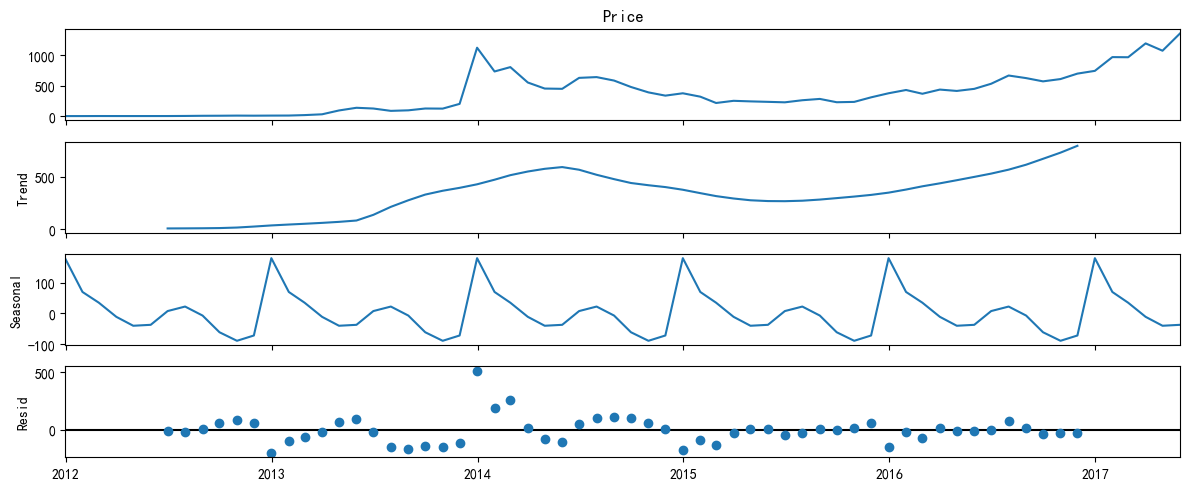

In [17]:
from statsmodels.tsa.seasonal import seasonal_decompose # 导入分解函数
# seasonal_decompose()使用移动平均线进行季节性分解
res = seasonal_decompose(df_month.Price)
# 设置图像显示大小
plt.rcParams['figure.figsize'] = 12, 5
# 绘制分解图形
res.plot()
# 得到如下的分解图形：原始数据、趋势数据、周期性数据、随机变量
plt.show()

由上图可知：比特币价格随时间数据总体呈现上升趋势并且大概以年为周期进行周期性波动。

### 4.3 时间序列数据平稳性检验

平稳性是时间序列中最重要的概念之一。一个平稳的序列意味着它的均值、方差和协方差不随时间变化。

**大多数的时间序列模型都假设时间序列是平稳的。**

时间序列数据平稳性检验方法，大概可以分为三类
1. 图形分析方法
2. 简单统计方法
3. 假设检验方法

#### 4.3.1 图形分析方法

图形分析方法是一种最基本、最简单直接的方法，即绘制图形，判断是否为平稳数据。

<Axes: xlabel='Timestamp'>

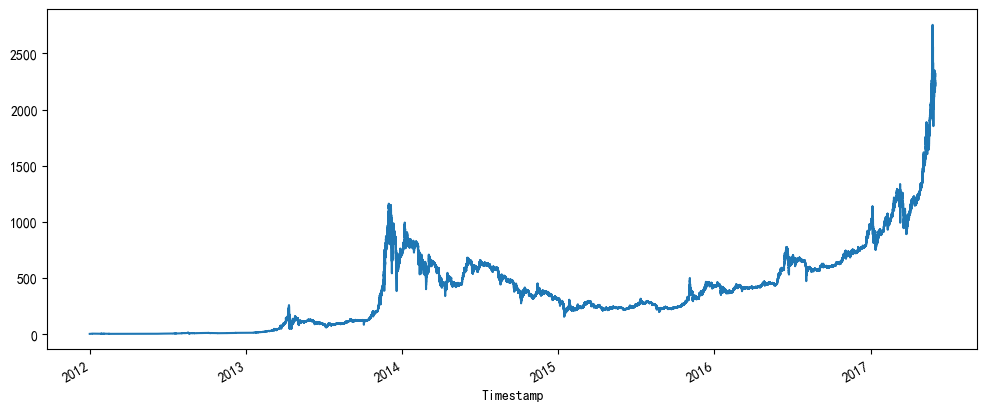

In [18]:
# 绘制价格数据的趋势图像
data['Price'].plot()

通过图形可以明显看到数据是非平稳数据。

#### 4.3.2 简单统计方法

平稳的序列的均值、方差和协方差不随时间变化。将序列前后拆成两个部分，分别计算这两个部分的均值和方差，对比看是否差异明显。

In [19]:
import numpy as np
# 获取数据集前1万个数据和后1万个数据
df1 = data.iloc[:10000]
df2 = data.iloc[-10000:]
print('df1的均值:{}，标准差：{}'.format(np.mean(df1['Price']),np.std(df1['Price'])))
print('df2的均值:{}，标准差：{}'.format(np.mean(df2['Price']),np.std(df2['Price'])))

df1的均值:5.37515083668488，标准差：0.716709307340843
df2的均值:2289.50310633263，标准差：161.62826539383767


#### 4.3.3 假设检验方法

比较常用的平稳性的假设检验方法为单位根平稳性检验（ADF检验），单位根检验是指检验序列中是否存在单位根，非平稳时间序列存在单位根。

In [20]:
from statsmodels.tsa.stattools import adfuller # 导入单位根检验函数
# 对于月采样的比特币价格数据进行单位根检验，检验数据的平稳性
p = adfuller(df_month.Price)[1]
print('单位根检验的p值为:',p)

单位根检验的p值为: 0.9454482394411


ADF检验的原假设是存在单位根，在显著性水平为95%的情况下，p值大于0.05，不拒绝原假设，即数据非平稳。


### 4.4 时间序列分解

> 来源：教材参考实现《数学建模算法与应用》15.5 节的练习稿（MIT，Zhanghan Wang），代码保持原样，仅按需改写数据路径并清空输出。

1. 平稳性Danile检验(base on Spearman秩相关系数) 418页
2. AR自回归预测模型. 经典预测模型有: 生长曲线, 指数平滑法. 这两种对于短期波动把握不高.  
AR自回归模型考虑了时间序列上的依存性, 又考虑了随机波动的干扰性, 对短期趋势预测准确率较高.  
类似的还有MA, ARMA. 暂未了解.  

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# 编秩函数
def get_rank(data, columns, ascending=True, R=np.zeros(1)):
    if data.ndim == 1:
        tempdata = np.array(data)[:,None]
    if not R.any():
        R = np.zeros(tempdata.shape)
    for i in columns:
        arg = tempdata[:,i].argsort(axis=0)
        if not ascending:
            arg = arg[::-1]
        begin, end = 0, 0
        # 找从begin开始相同项, 用end标记最后一个相同项的下一个
        while begin < len(arg):
            while end < len(arg) and tempdata[arg[end]][i] == tempdata[arg[begin]][i]:
                end += 1
            for j in range(begin, end):
                R[arg[j]][i] = (begin + end + 1) / 2
            begin = end
    return R.reshape(data.shape)

# 作n阶差分折线图
def diff_plot(y, n, scale=3):
    if y.shape[0] < n:
        print('Error')
        return
    for i in range(n):
        y = np.array([y[i]-y[i-1] if i != 0 else y[0] for i in range(y.shape[0])])
    plt.figure()
    plt.ylim(y.mean()-(y.max()-y.min())*scale, (y.max()-y.min())*scale+y.max())
    plt.plot(np.linspace(0, y.shape[0]-1, y.shape[0]), y)
    plt.title('{} Order Difference of Data'.format(n))
    plt.show()

T =  inf


C:\Users\yohoten\AppData\Local\Temp\ipykernel_30884\835623547.py:14: RuntimeWarning: divide by zero encountered in scalar divide
  T = qs*np.sqrt(at.shape[0]-2) / (np.sqrt(1-qs**2))


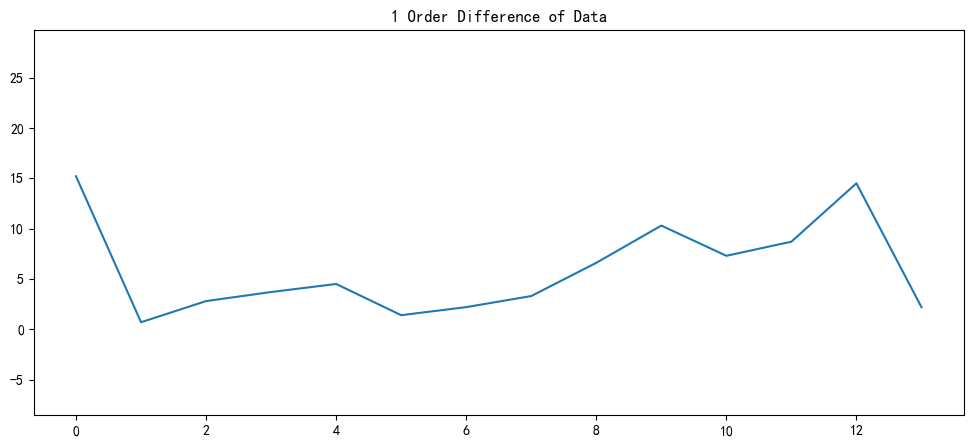

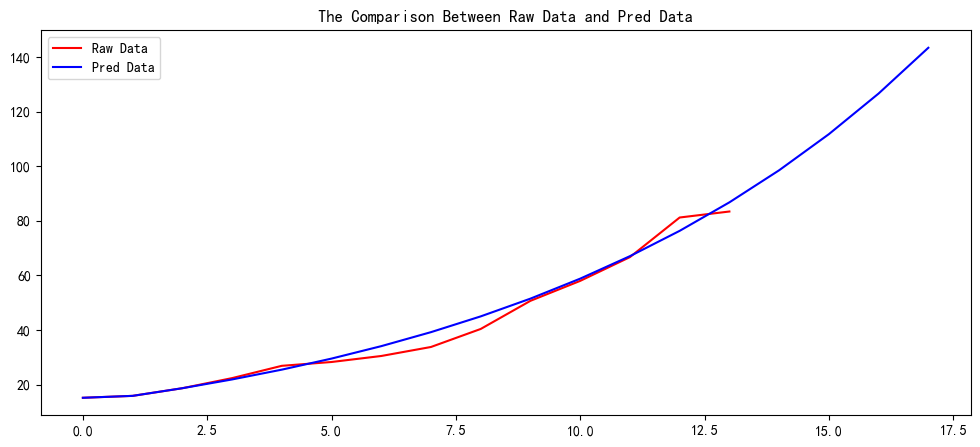

In [22]:
# 15.5.2 税收收入AR预测模型

import numpy as np
import matplotlib.pyplot as plt

at = np.array([15.2, 15.9, 18.7, 22.4, 26.9, 28.3, 30.5, 33.8, 40.4, 50.7, 58, 66.7, 81.2, 83.4])

# 1.检验序列是否平稳
# 计算秩
Rt = get_rank(at, columns=[0], ascending=True)
# 计算Spearman相关系数qs
qs = 1 - 6*(sum([(i+1-Rt[i])**2 for i in range(Rt.shape[0])]))/(at.shape[0]*(at.shape[0]**2-1))
# 计算统计量T
T = qs*np.sqrt(at.shape[0]-2) / (np.sqrt(1-qs**2))
print('T = ', T)
# 按照书上的一些判断可以知道序列非平稳.

# 先画折线图, 书上说可由此看出一阶差分时间序列是平稳的. 不太理解.
diff_plot(at, 1, scale=1)

# 用差分方程模型(似乎就是所谓AR模型?)
y = at[2:]
x = np.array([at[1:-1], at[0:-2], np.ones(at.shape[0]-2)]).T
C = np.matmul(np.linalg.inv(np.matmul(x.T, x)), np.matmul(x.T, y))

pred_at = at[:3]
for i in range(15):
    pred_at = np.r_[pred_at, [C[0] * pred_at[pred_at.shape[0]-1] + C[1] * pred_at[pred_at.shape[0]-2] + C[2]]]

plt.figure()
plt.plot(np.linspace(0, at.shape[0]-1, at.shape[0]), at, c='red', label='Raw Data')
plt.plot(np.linspace(0, pred_at.shape[0]-1, pred_at.shape[0]), pred_at, c='blue', label='Pred Data')
plt.legend()
plt.title('The Comparison Between Raw Data and Pred Data')
plt.show()

### 4.5 时间序列分析提纲

> 来源：教材参考实现《数学建模算法与应用》第 08 章的练习稿（MIT，Zhanghan Wang），代码保持原样，仅按需改写数据路径并清空输出。

#### 1.1 移动平均法(168页): 
只适合做近期预测, 而且要求预测目标发展趋势变化不大.
1. 当预测目标基本趋势是在某一水平上下波动时, 可以用一次移动平均法.
2. 当预测目标基本趋势与某一线性模型吻合时, 可以用二次移动平均法.

#### 1.2 指数平滑法(169页): 一般有一,二,三次指数平滑法    

## 5. 小结

本次实验介绍了时间序列数据的处理、简单分析和分解，并使用三种方法检验时间序列数据的平稳性。

通过本次实验需要掌握以下内容：

- 掌握时间序列数据的处理
- 掌握时间序列数据的分析和分解
- 掌握时间序列数据的平稳性检验
